# Rayleigh-Ritz

## Problem
$$
-y'' + \pi^2 y = 2\pi^2 \sin(\pi x), \quad y(0)=y(1)=0
$$
Exact solution $y = \sin(\pi x)$.

## Discretization
Piecewise-linear hat functions on `ne` elements of width $h$. Each element gives

$$
K_e = \frac{1}{h}\begin{bmatrix} 1 & -1 \\ -1 & 1 \end{bmatrix} + \pi^2 \frac{h}{6}\begin{bmatrix} 2 & 1 \\ 1 & 2 \end{bmatrix}
$$

and the load vector comes from 3-point Gauss-Legendre quadrature. The finite difference version of the same problem is used for comparison.

## Code

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from fem_1d import rayleigh_ritz, fd_reaction

In [2]:
q = np.pi**2
f = lambda x: 2*np.pi**2*np.sin(np.pi*x)
gp = np.array([-np.sqrt(3/5), 0, np.sqrt(3/5)])
gw = np.array([5/9, 8/9, 5/9])

In [3]:
def l2_err(x, y):
    h = x[1]-x[0]
    s = 0
    for e in range(len(x)-1):
        xq = (x[e]+x[e+1])/2 + gp*h/2
        yh = y[e] + (y[e+1]-y[e])*(xq-x[e])/h
        s += np.sum(gw*(yh-np.sin(np.pi*xq))**2)*h/2
    return np.sqrt(s)

In [4]:
results = []
for ne in [4, 8, 16, 32]:
    x, y = rayleigh_ritz(ne, f, q)
    xf, yf = fd_reaction(ne, f, q)
    results.append({'ne': ne,
                    'fem_max': np.linalg.norm(y-np.sin(np.pi*x), np.inf),
                    'fem_L2': l2_err(x, y),
                    'fd_max': np.linalg.norm(yf-np.sin(np.pi*xf), np.inf)})
df = pd.DataFrame(results)
df['order'] = np.log2(df['fem_max'].shift()/df['fem_max'])
df

,ne,fem_max,fem_L2,fd_max,order
0,4,0.025524,0.025124,0.025830,NaN
1,8,0.006417,0.006142,0.006434,1.991992
2,16,0.001606,0.001527,0.001607,1.998463
3,32,0.000402,0.000381,0.000402,1.999643


### Convergence

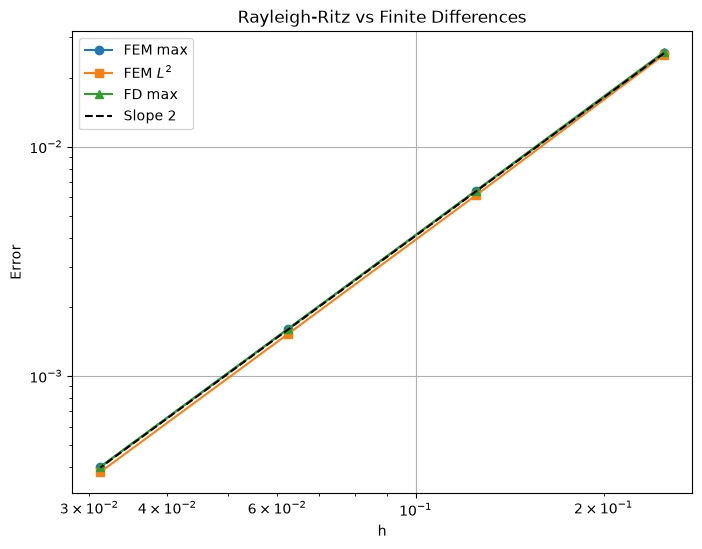

In [5]:
h = 1/df['ne'].values
plt.figure(figsize=(8, 6))
plt.loglog(h, df['fem_max'], 'o-', label="FEM max")
plt.loglog(h, df['fem_L2'], 's-', label=r"FEM $L^2$")
plt.loglog(h, df['fd_max'], '^-', label="FD max")
plt.loglog(h, df['fem_max'][0]*(h/h[0])**2, 'k--', label="Slope 2")
plt.xlabel("h")
plt.ylabel("Error")
plt.title("Rayleigh-Ritz vs Finite Differences")
plt.legend()
plt.grid(True)
plt.savefig("../figures/03_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion
Both the max and L2 errors are second order. FD gives almost the same error as FEM on these grids, so FEM has no real advantage for this problem.